# 04. Programmable aperture and multiplexed capture

A programmable aperture opens a different set of cells in each exposure, so one camera can record every view of the light field over time. If each shot opens about half the cells, it collects far more light than a shot through one cell, and the views can be recovered with a known matrix inverse. Whether this helps depends on the noise, and the slide-29 comparison with the plenoptic camera is where that question comes up. This notebook builds the S-matrix patterns, optimises patterns for nine cells, simulates noisy captures, demultiplexes them, compares the noise with the closed forms, and refocuses the recovered light field.

In [1]:
%matplotlib inline
# JPEG keeps the executed notebooks small (plots are photographs of textures).
%config InlineBackend.figure_format = 'jpeg'
import sys, pathlib
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 80
# Make `import lf` work whether Jupyter was started in the project root or in notebooks/.
_cwd = pathlib.Path.cwd().resolve()
ROOT = _cwd.parent if _cwd.name == 'notebooks' else _cwd
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import lf
from lf import synthetic, multiplex as mx, refocus, utils

np.set_printoptions(precision=3, suppress=True)

## S-matrix algebra

For $n = 7$, the S-matrix $S$ is a 0/1 matrix with $(n+1)/2$ open cells per row, and it satisfies $S^\top S = \frac{n+1}{4}(I + J)$ and $S^{-1} = \frac{2}{n+1}(2S^\top - J)$, where $J$ is the all-ones matrix. We check both identities numerically, and the trace of $(S^\top S)^{-1}$, which sets the read-noise penalty.

[[1 0 1 0 1 0 1]
 [0 1 1 0 0 1 1]
 [1 1 0 0 1 1 0]
 [0 0 0 1 1 1 1]
 [1 0 1 1 0 1 0]
 [0 1 1 1 1 0 0]
 [1 1 0 1 0 0 1]]
open cells per row : [4 4 4 4 4 4 4]
S^T S == (n+1)/4 (I + J): True
S^-1 == 2/(n+1) (2 S^T - J): True
tr((S^T S)^-1) = 3.0625 | 4 n^2 / (n+1)^2 = 3.0625


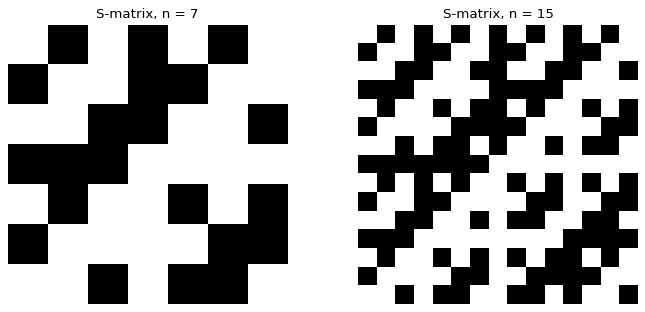

In [2]:
n = 7
S = mx.s_matrix(n)
print(S.astype(int))
print('open cells per row :', S.sum(1).astype(int))
J = np.ones((n, n)); I = np.eye(n)
print('S^T S == (n+1)/4 (I + J):', np.allclose(S.T @ S, (n + 1) / 4 * (I + J)))
print('S^-1 == 2/(n+1) (2 S^T - J):', np.allclose(np.linalg.inv(S), 2 / (n + 1) * (2 * S.T - J)))
print('tr((S^T S)^-1) =', round(float(np.trace(np.linalg.inv(S.T @ S))), 4),
      '| 4 n^2 / (n+1)^2 =', round(4 * n**2 / (n + 1) ** 2, 4))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(S, cmap='gray'); axes[0].set_title('S-matrix, n = 7'); axes[0].axis('off')
axes[1].imshow(mx.s_matrix(15), cmap='gray'); axes[1].set_title('S-matrix, n = 15'); axes[1].axis('off')
plt.tight_layout()

Both identities hold exactly, so the S-matrix inverse is cheap and the 7-cell design has the read-noise factor $4n^2/(n+1)^2 \approx 3.06$ instead of $n = 7$ for sequential capture.

## Patterns for nine cells

No S-matrix exists for $n = 9$, so `optimize_patterns` runs a simulated-annealing search on the read-noise objective $\mathrm{tr}((W^\top W)^{-1})$. We use a short run here; the result is a 9 x 9 pattern matrix with one row per shot.

open fraction: 0.49
objective tr((W^T W)^-1): optimised = 3.75 | identity = 9.0


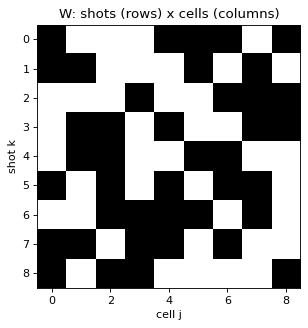

In [3]:
W_opt, obj = mx.optimize_patterns(9, iters=5000, noise='read', rng=0)
print('open fraction:', round(float(W_opt.mean()), 2))
print('objective tr((W^T W)^-1): optimised =', round(obj, 3),
      '| identity =', round(float(np.trace(np.linalg.inv(np.eye(9)))), 3))
fig, ax = plt.subplots(figsize=(4.5, 4.2))
ax.imshow(W_opt, cmap='gray', interpolation='nearest')
ax.set_title('W: shots (rows) x cells (columns)'); ax.set_xlabel('cell j'); ax.set_ylabel('shot k')
plt.tight_layout()

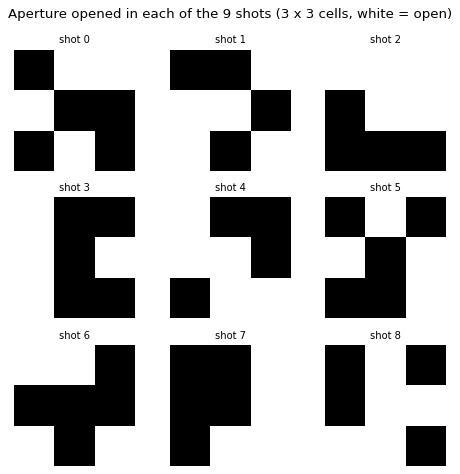

In [4]:
L = synthetic.synthetic_light_field(n_views=3, size=96)
fig, axes = plt.subplots(3, 3, figsize=(6, 6))
for k, ax in enumerate(axes.ravel()):
    ap = mx.pattern_to_aperture(W_opt[k], (3, 3))
    ax.imshow(ap, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
    ax.set_title(f'shot {k}', fontsize=9); ax.axis('off')
fig.suptitle('Aperture opened in each of the 9 shots (3 x 3 cells, white = open)')
plt.tight_layout()

Each shot opens about half the cells, in a pattern that looks random but is chosen to minimise the read-noise objective. Sequential capture would instead open one cell per shot.

## Capture with noise, then demultiplex

We simulate both designs with the same total exposure $T = 1$. The sequential camera opens one cell per shot, so each shot has $\tau = T/9$; the multiplexed camera opens about half the cells, but each shot still has $\tau = T/9$. `demultiplex` applies $W^+$ to the shots and rescales by $\tau$.

scheme                       PSNR vs clean [dB]
sequential (identity)                     19.15
multiplexed (optimised)                   19.65


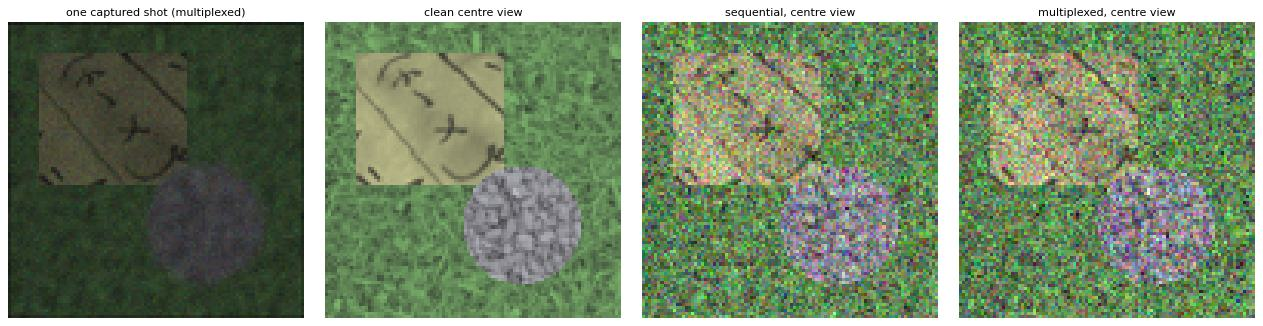

In [5]:
Y_mux = mx.capture(L, W_opt, total_exposure=1.0, photon_scale=1000, read_noise=0.01, rng=0)
Y_seq = mx.capture(L, np.eye(9), total_exposure=1.0, photon_scale=1000, read_noise=0.01, rng=0)
est_mux = mx.demultiplex(Y_mux, W_opt, exposure_per_shot=1.0 / 9)
est_seq = mx.demultiplex(Y_seq, np.eye(9), exposure_per_shot=1.0 / 9)

print(f"{'scheme':26s} {'PSNR vs clean [dB]':>20s}")
for name, est in [('sequential (identity)', est_seq), ('multiplexed (optimised)', est_mux)]:
    print(f"{name:26s} {utils.psnr(est.views, L.views):20.2f}")

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
panels = [('one captured shot (multiplexed)', Y_mux[0]), ('clean centre view', L.center_view),
          ('sequential, centre view', est_seq.center_view), ('multiplexed, centre view', est_mux.center_view)]
for ax, (title, img) in zip(axes, panels):
    ax.imshow(np.clip(img, 0, 1)); ax.set_title(title, fontsize=10); ax.axis('off')
plt.tight_layout()

At the same total exposure, the multiplexed reconstruction is only slightly better in PSNR here (19.7 against 19.2 dB), in this small 3 x 3 example with photon noise. Each multiplexed shot is much brighter than a sequential shot, but the inversion mixes the noise back in, so the net gain under photon noise is small.

## Expected noise versus simulation

`expected_mse` gives the closed-form per-sample MSE for read noise and for photon noise. `simulate_snr` runs the full capture and demultiplex to measure the same quantity. We check the two regimes separately and include the plenoptic baseline, which records every sample for the full $T$.

In [6]:
x_bar = L.views.reshape(9, -1).mean(1)
cases = [('sequential (identity)', np.eye(9), 1 / 9, False),
         ('multiplexed (optimised)', W_opt, 1 / 9, False),
         ('plenoptic baseline', np.eye(9), 1.0, True)]
print(f"{'scheme':24s} {'read: expected':>15s} {'read: simulated':>16s} {'photon: expected':>17s} {'photon: simulated':>18s}")
for name, W, tau, pl in cases:
    e_r = mx.expected_mse(W, noise='read', sigma_r=0.01, exposure=tau)
    s_r = mx.simulate_snr(L, W, total_exposure=1.0, photon_scale=None, read_noise=0.01,
                          trials=20, rng=1, plenoptic=pl)['mse']
    e_p = mx.expected_mse(W, noise='photon', x_mean=x_bar, exposure=tau, photon_scale=1000.0)
    s_p = mx.simulate_snr(L, W, total_exposure=1.0, photon_scale=1000.0, read_noise=0.0,
                          trials=20, rng=1, plenoptic=pl)['mse']
    print(f"{name:24s} {e_r:15.2e} {s_r:16.2e} {e_p:17.2e} {s_p:18.2e}")
print('S-matrix SNR gain over sequential (read noise, n = 9 optimised W):',
      round(mx.snr_gain(W_opt, noise='read'), 2))

scheme                    read: expected  read: simulated  photon: expected  photon: simulated


sequential (identity)           8.10e-03         8.10e-03          4.05e-03           4.05e-03


multiplexed (optimised)         3.38e-03         3.37e-03          7.43e-03           7.42e-03


plenoptic baseline              1.00e-04         1.00e-04          4.50e-04           4.50e-04
S-matrix SNR gain over sequential (read noise, n = 9 optimised W): 1.55


The expected and simulated MSEs agree to within about 1 % in every row, which validates the closed forms. Under read noise the multiplexed scheme has about 2.4 times lower MSE than sequential capture, while under photon noise it has about 1.8 times higher MSE, which is the trade-off the next section explains. The plenoptic baseline has the lowest MSE in both regimes, but it ignores its loss of spatial resolution.

## Slide 29, revisited

Slide 29 quotes multiplexed SNR as $\mathrm{SNR}_p/\sqrt{2}$ under photon noise and $\mathrm{SNR}_p/2$ under read noise, but the sequential column uses a per-pixel convention, so the two columns are not directly comparable. Under one consistent convention, multiplexing helps mainly with read noise, by about $\sqrt{N}/2$ over sequential capture, and it is about $\sqrt{2}$ worse than sequential for photon noise on a uniform scene (1.35 times for the optimised 9-cell pattern here; see [docs/08](../docs/08_programmable_aperture.md), section 2.4).

In [7]:
tt = mx.theory_table(9, W=W_opt)
print(f"{'regime':8s} {'scheme':12s} {'slide claim':>12s} {'per pixel':>11s} {'binned to M/N':>14s}")
for regime in ['photon', 'read']:
    slide = tt['slide'][regime]
    for key, label, s_val in [('pa_nomux', 'no mux', slide[1]), ('pa_mux', 'mux', slide[2])]:
        row = tt[regime][key]
        print(f"{regime:8s} {label:12s} {s_val:12.3f} {row['snr_rel']:11.3f} {row['snr_rel_binned']:14.3f}")
print('plenoptic reference: SNR relative to itself = 1 in every row')

regime   scheme        slide claim   per pixel  binned to M/N
photon   no mux              0.333       0.333          1.000
photon   mux                 0.707       0.246          0.739
read     no mux              0.111       0.111          0.333
read     mux                 0.500       0.172          0.516
plenoptic reference: SNR relative to itself = 1 in every row


The table prints the closed forms in the three columns that matter: the slide's own claim, the per-pixel SNR relative to the plenoptic sample, and the same after binning $N$ pixels to get $M/N$ outputs. Only the binned column is directly comparable with the slide's multiplexed row.

## Refocusing the recovered light field

The demultiplexed light fields are ordinary `LightField` objects, so refocusing works on them unchanged. We refocus the clean light field, the sequential reconstruction and the multiplexed reconstruction on the gravel plane at $\alpha = 1.5$, and score each against the clean image.

source                      PSNR vs clean refocus [dB]
sequential                                       32.08
multiplexed                                      32.54


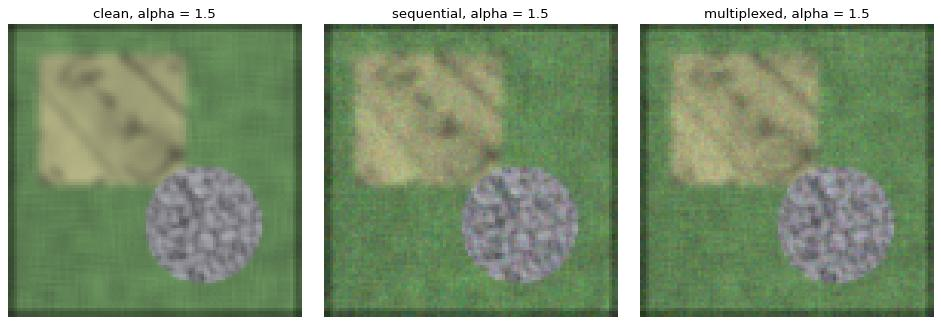

In [8]:
alpha = 1.5
ref_clean = refocus.refocus(L, alpha)
ref_seq = refocus.refocus(est_seq, alpha)
ref_mux = refocus.refocus(est_mux, alpha)
print(f"{'source':26s} {'PSNR vs clean refocus [dB]':>27s}")
print(f"{'sequential':26s} {utils.psnr(ref_seq, ref_clean):27.2f}")
print(f"{'multiplexed':26s} {utils.psnr(ref_mux, ref_clean):27.2f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (title, img) in zip(axes, [('clean', ref_clean), ('sequential', ref_seq), ('multiplexed', ref_mux)]):
    ax.imshow(np.clip(img, 0, 1)); ax.set_title(f'{title}, alpha = {alpha}'); ax.axis('off')
plt.tight_layout()

Both refocus well, and the multiplexed one is slightly closer to the clean refocus (32.5 against 32.1 dB), the same ranking as before.

## Where to go next

Read [docs/08_programmable_aperture.md](../docs/08_programmable_aperture.md) for the derivations, the choice of $W$, and the full slide-29 analysis. The matching tab in the Streamlit explorer (`streamlit run app/streamlit_app.py`) lets you change the pattern and the noise level. Notebook 05 extends the light field to high dynamic range.